# Imports y configuracion 


In [2]:
import os
import numpy as np
import cv2 as cv
import mediapipe as mp
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt



BASE_DIR = os.getcwd()
MODEL_DIR = os.path.abspath(os.path.join(BASE_DIR, '..', 'models', 'hand_landmarker.task'))
DATASET_DIR = os.path.abspath(os.path.join(BASE_DIR, '..', 'data', 'Senas de LSCh.v5i.tensorflow'))

BaseOptions = python.BaseOptions
HandLandmarker = vision.HandLandmarker
HandLandmarkerOptions = vision.HandLandmarkerOptions
VisionRunningMode = vision.RunningMode

# Grafo de conexiones (reutilizado de main.py)
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),          # pulgar
    (0, 5), (5, 6), (6, 7), (7, 8),          # indice
    (5, 9), (9, 10), (10, 11), (11, 12),     # medio
    (9, 13), (13, 14), (14, 15), (15, 16),   # anular
    (13, 17), (17, 18), (18, 19), (19, 20),  # menique
    (0, 17),                                 # palma
]

# Excluimos letras que requieren movimiento (J, Z)
LETRAS_EXCLUIDAS = {'J', 'Z'}
LABELS = [letra for letra in 'ABCDEFGHIJKLMNOPQRSTUVWXYZ' if letra not in LETRAS_EXCLUIDAS]

LANDMARK_NAMES = [
    'muneca',
    'pulgar_cmc', 'pulgar_mcp', 'pulgar_ip', 'pulgar_tip',
    'indice_mcp', 'indice_pip', 'indice_dip', 'indice_tip',
    'medio_mcp', 'medio_pip', 'medio_dip', 'medio_tip',
    'anular_mcp', 'anular_pip', 'anular_dip', 'anular_tip',
    'menique_mcp', 'menique_pip', 'menique_dip', 'menique_tip',
]

def get_hand_data(result):
    """Extrae los datos posicionales del grafo de la mano detectada."""
    hands = []
    if result is None or not result.hand_landmarks:
        return hands
    for hand in result.hand_landmarks:
        coords = np.array([[lm.x, lm.y, lm.z] for lm in hand], dtype=np.float32)
        hands.append({'coords': coords})
    return hands

def draw_hand_graph(frame, hands):
    """Dibuja los landmarks (nodos) y conexiones (aristas) de cada mano detectada."""
    h, w = frame.shape[:2]
    for hand in hands:
        pts = [(int(x * w), int(y * h)) for x, y, _ in hand['coords']]
        for a, b in HAND_CONNECTIONS:
            cv.line(frame, pts[a], pts[b], (0, 255, 0), 2)
        for idx, p in enumerate(pts):
            cv.circle(frame, p, 4, (0, 0, 255), -1)
            cv.putText(frame, str(idx), (p[0] + 5, p[1] - 5),
                       cv.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
    return frame




def detectar_mano_imagen(frame, row, landmarker):
    """Intenta detectar la mano en la imagen completa; si falla, recorta usando el bounding box del CSV."""
    frame2RGB = cv.cvtColor(frame, cv.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame2RGB)
    result = landmarker.detect(mp_image)
    hands = get_hand_data(result)
    if hands:
        return hands, frame

    h, w = frame.shape[:2]
    margin = 60
    x1 = max(0, int(row['xmin']) - margin)
    y1 = max(0, int(row['ymin']) - margin)
    x2 = min(w, int(row['xmax']) + margin)
    y2 = min(h, int(row['ymax']) + margin)
    crop = frame[y1:y2, x1:x2].copy()
    crop_rgb = cv.cvtColor(crop, cv.COLOR_BGR2RGB)
    result = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=crop_rgb))
    hands = get_hand_data(result)
    return hands, crop


options = HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=MODEL_DIR),
    running_mode=VisionRunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.35,
    min_hand_presence_confidence=0.30,
    min_tracking_confidence=0.30,
)


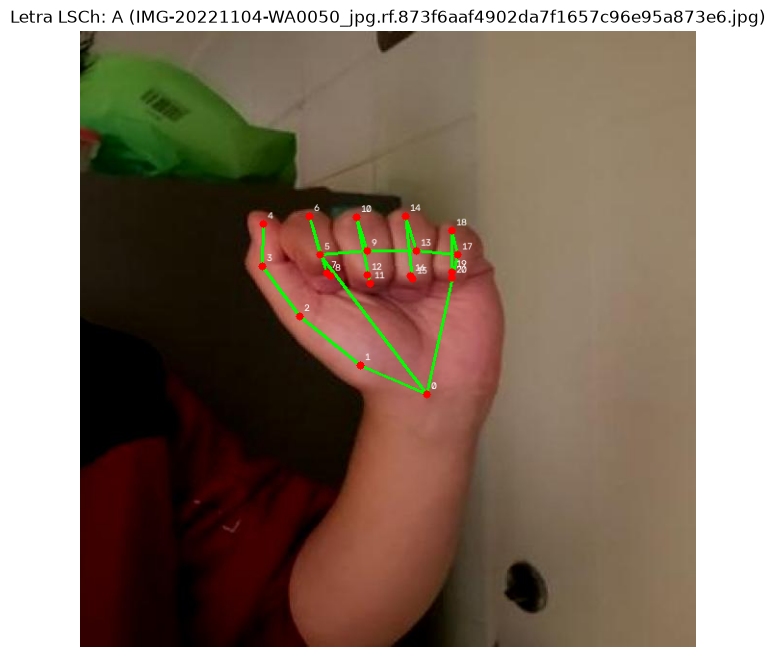

(array([ 0.        ,  0.        ,  0.        , -0.37302807, -0.163442  ,
       -0.17136793, -0.7132688 , -0.43936566, -0.2543095 , -0.9237768 ,
       -0.7195793 , -0.3252782 , -0.91886276, -0.955325  , -0.34448683,
       -0.5972462 , -0.7813485 , -0.12452239, -0.66060776, -0.9971245 ,
       -0.29567698, -0.5597032 , -0.68080884, -0.32913497, -0.5393112 ,
       -0.6618453 , -0.3367886 , -0.3353731 , -0.80699635, -0.09904861,
       -0.39487815, -0.99374306, -0.27369362, -0.31745085, -0.61885697,
       -0.25406158, -0.33362114, -0.67029524, -0.21449257, -0.05895783,
       -0.80521566, -0.10568088, -0.12000611, -1.        , -0.27637672,
       -0.08304719, -0.64979255, -0.15928411, -0.09272982, -0.66565555,
       -0.05251855,  0.17150411, -0.7806152 , -0.12824391,  0.14181133,
       -0.91886985, -0.20539632,  0.13710473, -0.68492687, -0.11824042,
        0.13831525, -0.6545679 , -0.03959389], dtype=float32), 'A')


In [3]:

def normalizacion_etiquetado(hands, label):
    if not hands:
        return None, None
    coords = hands[0]['coords']
    coords = coords - coords[0]
    absmax = np.max(np.abs(coords))
    norm_coords = (coords / absmax).flatten()
    return norm_coords, label
# Prueba visual con una imagen del dataset chileno (LSCh) leyendo _annotations.csv
train_csv = os.path.join(DATASET_DIR, 'train', '_annotations.csv')
df_train_ann = pd.read_csv(train_csv)

sample_row = df_train_ann.iloc[0]
img_path = os.path.join(DATASET_DIR, 'train', sample_row['filename'])
label_muestra = str(sample_row['class']).upper()
frame = cv.imread(img_path)

with HandLandmarker.create_from_options(options) as landmarker:
    hands, frame_usado = detectar_mano_imagen(frame.copy(), sample_row, landmarker)

draw_hand_graph(frame_usado, hands)

plt.figure(figsize=(8, 8))
plt.title(f"Letra LSCh: {label_muestra} ({sample_row['filename']})")
plt.imshow(cv.cvtColor(frame_usado, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

print(normalizacion_etiquetado(hands, label_muestra))

# Extraccion de coordenadas y creacion del CSV (Letras estaticas LSCh)


In [4]:
# Nombres de las 63 columnas de coordenadas: muneca_x, muneca_y, muneca_z, ..., menique_tip_z
COORD_COLS = [f'{nombre}_{eje}' for nombre in LANDMARK_NAMES for eje in ('x', 'y', 'z')]
OUTPUT_CSV = os.path.abspath(os.path.join(BASE_DIR, '..', 'data', 'lsch_coordenadas_estaticas.csv'))

def procesar_dataset_lsch(splits=('train', 'valid', 'test')):
    if os.path.isfile(OUTPUT_CSV):
        print(f"El dataset ya existe. Cargando desde: {OUTPUT_CSV}")
        return pd.read_csv(OUTPUT_CSV)

    filas = []
    with HandLandmarker.create_from_options(options) as landmarker:
        for split in splits:
            split_dir = os.path.join(DATASET_DIR, split)
            csv_path = os.path.join(split_dir, '_annotations.csv')
            if not os.path.exists(csv_path):
                continue

            df_ann = pd.read_csv(csv_path)
            detectadas = 0
            total_estaticas = 0

            for _, row in df_ann.iterrows():
                label = str(row['class']).strip().upper()
                if label in LETRAS_EXCLUIDAS:
                    continue

                total_estaticas += 1
                img_path = os.path.join(split_dir, row['filename'])
                frame = cv.imread(img_path)
                if frame is None:
                    continue

                hands, _ = detectar_mano_imagen(frame, row, landmarker)
                norm_coords, lbl = normalizacion_etiquetado(hands, label)
                if norm_coords is not None:
                    detectadas += 1
                    registro = {col: val for col, val in zip(COORD_COLS, norm_coords)}
                    registro['label'] = lbl
                    registro['split'] = split
                    filas.append(registro)

            print(f"[{split}] Manos detectadas: {detectadas}/{total_estaticas} ({detectadas/max(1, total_estaticas)*100:.1f}%)")

    df = pd.DataFrame(filas)
    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\nCSV guardado en: {OUTPUT_CSV} con {len(df)} muestras.")
    return df

df_coordenadas = procesar_dataset_lsch()
df_coordenadas.head()

El dataset ya existe. Cargando desde: c:\Users\basti\Desktop\PDI\proyecto-PDI\data\lsch_coordenadas_estaticas.csv


,muneca_x,muneca_y,muneca_z,pulgar_cmc_x,pulgar_cmc_y,pulgar_cmc_z,pulgar_mcp_x,pulgar_mcp_y,pulgar_mcp_z,pulgar_ip_x,...,menique_pip_y,menique_pip_z,menique_dip_x,menique_dip_y,menique_dip_z,menique_tip_x,menique_tip_y,menique_tip_z,label,split
0,0.0,0.0,0.0,-0.373028,-0.163442,-0.171368,-0.713269,-0.439366,-0.254310,-0.923777,...,-0.918870,-0.205396,0.137105,-0.684927,-0.118240,0.138315,-0.654568,-0.039594,A,train
1,0.0,0.0,0.0,-0.111628,0.250593,0.180930,-0.071790,0.422926,0.264320,0.030348,...,0.469022,0.219414,0.406075,0.448553,0.332661,0.359935,0.406820,0.413362,N,train
2,0.0,0.0,0.0,-0.183837,0.169053,0.025842,-0.181448,0.362759,0.047203,-0.070292,...,0.483592,0.057922,0.207575,0.452157,0.085035,0.172982,0.404512,0.107834,N,train
3,0.0,0.0,0.0,-0.207766,-0.094768,-0.101700,-0.370894,-0.243559,-0.144500,-0.425906,...,-0.660195,0.000973,-0.006568,-0.752979,-0.017277,-0.033765,-0.839190,-0.034530,B,train
4,0.0,0.0,0.0,-0.184779,-0.027036,-0.092117,-0.360960,-0.171185,-0.146899,-0.425695,...,-0.620895,-0.171417,0.084036,-0.726143,-0.196425,0.064836,-0.819447,-0.212965,B,train


# Entrenamiento (utilizando una MLP)

In [5]:
df_entenamiento,df_val ,df_test  = df_coordenadas[df_coordenadas["split"]=="train"].drop(columns='split'),df_coordenadas[df_coordenadas["split"]=="valid"].drop(columns='split'),df_coordenadas[df_coordenadas["split"]=="test"].drop(columns='split')
print(df_entenamiento['label'].value_counts()) # desbalanceo de clases  
pesos_por_clase = compute_class_weight(class_weight="balanced", classes=np.unique(df_entenamiento["label"]), y=df_entenamiento["label"])
pesos_por_clase  = dict(enumerate(pesos_por_clase))
display(df_entenamiento.head())

label
A    151
B    150
L    143
E    136
C    136
T    103
Q    102
M     97
O     93
N     88
R     88
G     79
U     71
Y     70
W     65
V     57
F     53
D     53
P     51
I     47
K     46
H     45
S     44
X     41
Name: count, dtype: int64


,muneca_x,muneca_y,muneca_z,pulgar_cmc_x,pulgar_cmc_y,pulgar_cmc_z,pulgar_mcp_x,pulgar_mcp_y,pulgar_mcp_z,pulgar_ip_x,...,menique_pip_x,menique_pip_y,menique_pip_z,menique_dip_x,menique_dip_y,menique_dip_z,menique_tip_x,menique_tip_y,menique_tip_z,label
0,0.0,0.0,0.0,-0.373028,-0.163442,-0.171368,-0.713269,-0.439366,-0.254310,-0.923777,...,0.141811,-0.918870,-0.205396,0.137105,-0.684927,-0.118240,0.138315,-0.654568,-0.039594,A
1,0.0,0.0,0.0,-0.111628,0.250593,0.180930,-0.071790,0.422926,0.264320,0.030348,...,0.439329,0.469022,0.219414,0.406075,0.448553,0.332661,0.359935,0.406820,0.413362,N
2,0.0,0.0,0.0,-0.183837,0.169053,0.025842,-0.181448,0.362759,0.047203,-0.070292,...,0.245582,0.483592,0.057922,0.207575,0.452157,0.085035,0.172982,0.404512,0.107834,N
3,0.0,0.0,0.0,-0.207766,-0.094768,-0.101700,-0.370894,-0.243559,-0.144500,-0.425906,...,0.022530,-0.660195,0.000973,-0.006568,-0.752979,-0.017277,-0.033765,-0.839190,-0.034530,B
4,0.0,0.0,0.0,-0.184779,-0.027036,-0.092117,-0.360960,-0.171185,-0.146899,-0.425695,...,0.100071,-0.620895,-0.171417,0.084036,-0.726143,-0.196425,0.064836,-0.819447,-0.212965,B


In [ ]:

letras = 'ABCDEFGHIKLMNOPQRSTUVWXY'
cambios = {}

for i in range(len(letras)):
    cambios[letras[i]] = i
df_entenamiento['label'] = df_entenamiento['label'].replace(cambios).astype('int32')
df_val['label'] = df_val['label'].replace(cambios).astype('int32')
df_test['label'] = df_test['label'].replace(cambios).astype('int32')
display(df_entenamiento.head())

x_train,x_val,x_test = df_entenamiento.drop(columns='label').to_numpy(),df_val.drop(columns='label').to_numpy(),df_test.drop(columns='label').to_numpy()
y_train,y_val,y_test = df_entenamiento['label'].to_numpy(),df_val['label'].to_numpy(),df_test['label'].to_numpy()

,muneca_x,muneca_y,muneca_z,pulgar_cmc_x,pulgar_cmc_y,pulgar_cmc_z,pulgar_mcp_x,pulgar_mcp_y,pulgar_mcp_z,pulgar_ip_x,...,menique_pip_x,menique_pip_y,menique_pip_z,menique_dip_x,menique_dip_y,menique_dip_z,menique_tip_x,menique_tip_y,menique_tip_z,label
0,0.0,0.0,0.0,-0.373028,-0.163442,-0.171368,-0.713269,-0.439366,-0.254310,-0.923777,...,0.141811,-0.918870,-0.205396,0.137105,-0.684927,-0.118240,0.138315,-0.654568,-0.039594,0
1,0.0,0.0,0.0,-0.111628,0.250593,0.180930,-0.071790,0.422926,0.264320,0.030348,...,0.439329,0.469022,0.219414,0.406075,0.448553,0.332661,0.359935,0.406820,0.413362,12
2,0.0,0.0,0.0,-0.183837,0.169053,0.025842,-0.181448,0.362759,0.047203,-0.070292,...,0.245582,0.483592,0.057922,0.207575,0.452157,0.085035,0.172982,0.404512,0.107834,12
3,0.0,0.0,0.0,-0.207766,-0.094768,-0.101700,-0.370894,-0.243559,-0.144500,-0.425906,...,0.022530,-0.660195,0.000973,-0.006568,-0.752979,-0.017277,-0.033765,-0.839190,-0.034530,1
4,0.0,0.0,0.0,-0.184779,-0.027036,-0.092117,-0.360960,-0.171185,-0.146899,-0.425695,...,0.100071,-0.620895,-0.171417,0.084036,-0.726143,-0.196425,0.064836,-0.819447,-0.212965,1


# explicacion del diseño del modelo 
- La entrada sera un vector plano teniendo como entradas cada uno de los valores obtenidos del grafo ya normalizado 
- 



In [37]:
tf.random.set_seed(22)
modelo = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(63,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(24, activation='softmax')
])


modelo.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 32)             │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 24)             │           408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,984 (11.66 KB)

 Trainable params: 2,984 (11.66 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


In [39]:
historial = modelo.fit(
    x=x_train,
    y=y_train,
    validation_data=(x_val,y_val),
    class_weight=pesos_por_clase,
    epochs=80,
    batch_size=32,
    )


Epoch 1/80
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0786 - loss: 3.1329 - val_accuracy: 0.1034 - val_loss: 3.0070
Epoch 2/80
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1095 - loss: 2.9773 - val_accuracy: 0.1773 - val_loss: 2.7867
Epoch 3/80
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1558 - loss: 2.7988 - val_accuracy: 0.2512 - val_loss: 2.5829
Epoch 4/80
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2016 - loss: 2.6693 - val_accuracy: 0.3005 - val_loss: 2.4334
Epoch 5/80
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2275 - loss: 2.5577 - val_accuracy: 0.4138 - val_loss: 2.3109
Epoch 6/80
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2330 - loss: 2.4641 - val_accuracy: 0.3941 - val_loss: 2.1888
Epoch 7/80
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2389 - loss: 2.3624 - val_accuracy: 0.4384 - val_loss: 2.0851
Epoch 8/80
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2688 - loss: 2.2679 - val_accuracy: 0.4631 - val_loss:

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9524 - loss: 0.3653 


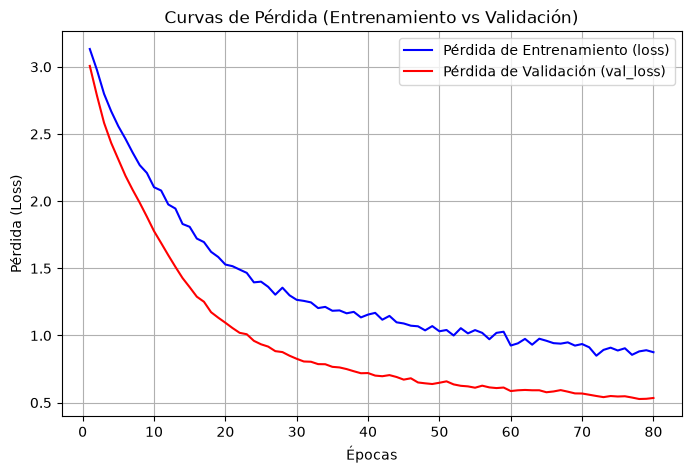

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/stepWARNING:tensorflow:5 out of the last 17 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000001F54F5D3BA0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


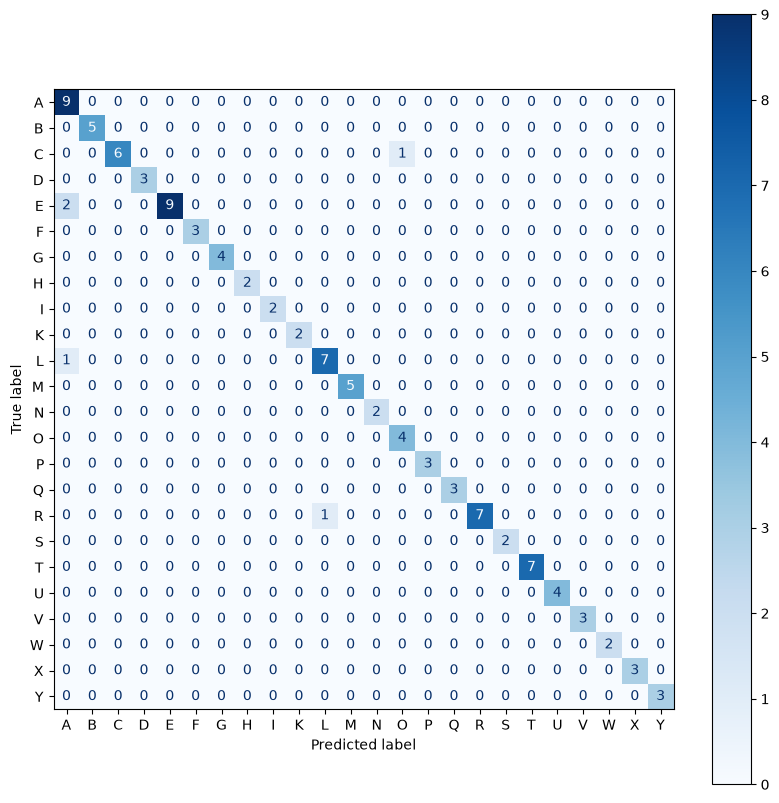

In [40]:
modelo.evaluate(x_test, y_test)

loss = historial.history['loss']
val_loss = historial.history['val_loss']
epocas = range(1,len(loss)+1)

plt.figure(figsize=(8, 5))
plt.plot(epocas, loss, label='Pérdida de Entrenamiento (loss)', color='blue')
plt.plot(epocas, val_loss, label='Pérdida de Validación (val_loss)', color='red')
plt.title('Curvas de Pérdida (Entrenamiento vs Validación)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

predicciones = modelo.predict(x_test)
y_pred = np.argmax(predicciones, axis=1)
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABELS)
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.show()


In [41]:
modelo.save(os.path.join(BASE_DIR, '..', 'models', 'mlp_lsch.keras'))